# WiPER Benchmarking — v6

Va usato con i grafi prodotti da **WiPER-DatasetGeneration v4** (finestre scorrevoli + metadati `action`, `rec_id`).

**Cosa cambia rispetto alla v5**

| # | v5 | v6 |
|---|---|---|
| 1 | Un solo protocollo di test (gallery = saluto, probe = tPose) | **4 protocolli**: cross-azione in entrambe le direzioni + **stessa azione** (leave-one-recording-out) per saluto e per tPose |
| 2 | Ogni finestra era una query | Le finestre sono **aggregate per registrazione** (media degli embedding): 1 query = 1 registrazione, nessuna correlazione tra finestre sovrapposte |
| 3 | Validazione = leave-one-out su tutto | Validazione con **gli stessi 4 protocolli** del test, sulle identità di D1 tenute fuori |
| 4 | Batch PK pescava K finestre a caso (potevano venire dalla stessa registrazione) | Il sampler pesca **K registrazioni diverse** per identità, poi una finestra per registrazione |
| 5 | Solo modello neurale + baseline non addestrata | Aggiunte baseline **handcrafted** (statistiche per sottoportante) e **handcrafted + LDA** |
| 6 | Normalizzazione `graph` (toglie anche il profilo statico per sottoportante) | `norm_mode`: `'none'` \| **`'scale'`** (default: toglie solo il guadagno, tiene il profilo statico) \| `'graph'` |
| 7 | — | Opzione **centering per azione** (sottrae la media degli embedding di ciascuna azione, senza etichette) riportata come riga separata |

I protocolli sono definiti sulle **registrazioni** (22 identità × 5 saluto + 5 tPose nel test):

* `cross`: gallery = saluto, probe = tPose
* `cross_rev`: gallery = tPose, probe = saluto
* `same_saluto`, `same_tpose`: ogni registrazione contro tutte le altre della stessa azione (esclusa se stessa)

> Se `same_*` è alto e `cross` è basso, il limite è il cambio di azione e non il modello. Con circa 110 query per protocollo, differenze di 3 punti di Rank-1 sono rumore.

## 1. Imports e configurazione

In [1]:
import os, re, copy, random
from collections import defaultdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option('display.max_columns', None); pd.set_option('display.width', 250)

from torch_geometric.data import Data, Batch
from torch_geometric.nn import GATConv, global_mean_pool, global_max_pool

CFG = dict(
    seed=42,
    # --- dati ---
    train_root='./output/GraphData/D1/',
    test_root='./output/GraphData/D2t/',
    num_nodes=52, seq_len=100,
    gallery_action='saluto', probe_action='tpose',
    val_id_fraction=0.25,      # frazione di identità di D1 tenute fuori per validazione (0 -> nessuna validazione, si usa l'ultima epoca)
    # --- sampling ---
    P=8, K=4, batches_per_epoch=20,
    # --- ottimizzazione ---
    n_epochs=100, lr=3e-4, weight_decay=5e-4, patience=25, grad_clip=1.0,
    select_on='mean',          # 'mean' = media della mAP sui 4 protocolli di validazione | 'cross' = solo cross-azione
    # --- modello ---
    norm_mode='scale',         # 'none' | 'scale' | 'graph'
    temporal_dim=64, hidden=64, heads=4, gat_out=128, emb_dim=128, dropout=0.2,
    graph_mode='band', band_k=4,
    # --- loss ---
    margin=0.3, ce_weight=1.0, label_smoothing=0.1, lambda_gc=0.005,
    # --- varie ---
    augment=True, monitor_test_every=5,
    save_dir='./output/models/',
)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

set_seed(CFG['seed'])
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device being used:', device)

device being used: cpu


## 2. Caricamento dati (tutti i grafi in RAM)

In [2]:
FNAME_RE = re.compile(r'^(?P<sid>[^_]+)_(?P<act>[A-Za-z]+)(?P<num>\d+)(?:_w(?P<win>\d+))?$')

def _scalar(v):
    if v is None: return None
    if isinstance(v, (list, tuple)): v = v[0]
    if torch.is_tensor(v): v = v.item()
    return v

def load_graph_folder(root):
    items = []
    for dirpath, _, files in os.walk(root):
        for f in sorted(files):
            if not f.endswith('.pt'):
                continue
            p = os.path.join(dirpath, f)
            d = torch.load(p, weights_only=False)
            m = FNAME_RE.match(os.path.splitext(f)[0])
            sid = _scalar(getattr(d, 'subject_id', None)) or (m.group('sid') if m else None)
            act = _scalar(getattr(d, 'action', None)) or (m.group('act') if m else None)
            num = _scalar(getattr(d, 'rec_num', None))
            num = int(num) if num is not None else (int(m.group('num')) if m else None)
            if sid is None or act is None or num is None:
                raise ValueError(f'{p}: mancano subject_id/action/rec_num. Rigenera i grafi con WiPER-DatasetGeneration v4.')
            act = str(act).lower()
            rec = _scalar(getattr(d, 'rec_id', None)) or f'{sid}_{act}{num}'
            items.append(dict(x=d.x.float(), edge_index=d.edge_index.long(), sid=str(sid), act=act,
                              rec=str(rec), folder=os.path.basename(os.path.normpath(dirpath)).lower()))
    return items

def make_graphs(items, label_map=None):
    return [Data(x=it['x'], edge_index=it['edge_index'],
                 y=torch.tensor([-1 if label_map is None else label_map[it['sid']]], dtype=torch.long)) for it in items]

def meta_of(items):
    return [dict(sid=it['sid'], act=it['act'], rec=it['rec']) for it in items]

train_all = load_graph_folder(CFG['train_root'])
test_all  = load_graph_folder(CFG['test_root'])
assert train_all, f"Nessun .pt in {CFG['train_root']}"
assert test_all,  f"Nessun .pt in {CFG['test_root']}"

shapes = {tuple(it['x'].shape) for it in train_all + test_all}
assert shapes == {(CFG['num_nodes'], CFG['seq_len'])}, f'x shapes inattese: {shapes}'

# --- split train / val per identità --------------------------------------
all_train_ids = sorted({it['sid'] for it in train_all})
rng = np.random.RandomState(CFG['seed'])
perm = rng.permutation(len(all_train_ids))
n_val = int(round(len(all_train_ids) * CFG['val_id_fraction']))
val_ids_set = {all_train_ids[i] for i in perm[:n_val]}

train_items = [it for it in train_all if it['sid'] not in val_ids_set]
val_items   = [it for it in train_all if it['sid'] in val_ids_set]
test_items  = test_all                                  # Probe + Gallery insieme: i protocolli rifanno le coppie per azione

train_ids = sorted({it['sid'] for it in train_items})
label_map = {s: i for i, s in enumerate(train_ids)}
n_classes = len(train_ids)

train_graphs = make_graphs(train_items, label_map)
train_labels = [label_map[it['sid']] for it in train_items]
train_recs   = [it['rec'] for it in train_items]
val_graphs,  val_meta  = make_graphs(val_items),  meta_of(val_items)
test_graphs, test_meta = make_graphs(test_items), meta_of(test_items)

def describe(name, items):
    ids = {it['sid'] for it in items}; recs = {it['rec'] for it in items}
    acts = defaultdict(set)
    for it in items: acts[it['act']].add(it['rec'])
    print(f"{name:6s}: {len(items):5d} finestre | {len(ids):2d} identità | {len(recs):3d} registrazioni "
          f"({', '.join(f'{a}: {len(r)}' for a, r in sorted(acts.items()))})")

describe('TRAIN', train_items); describe('VAL', val_items); describe('TEST', test_items)
assert not ({it['sid'] for it in train_all} & {it['sid'] for it in test_all}), 'Identità in comune fra D1 e test!'
print('Nessuna identità in comune fra D1 e test  OK')

TRAIN :   546 finestre | 16 identità | 160 registrazioni (saluto: 80, tpose: 80)
VAL   :   222 finestre |  6 identità |  60 registrazioni (saluto: 30, tpose: 30)
TEST  :   747 finestre | 22 identità | 220 registrazioni (saluto: 110, tpose: 110)
Nessuna identità in comune fra D1 e test  OK


## 3. Sampler (K registrazioni diverse per identità) e augmentation

In [3]:
class PKRecSampler:
    # P identità x K registrazioni diverse, una finestra casuale per registrazione.
    def __init__(self, labels, recs, P, K, batches_per_epoch):
        self.tree = defaultdict(lambda: defaultdict(list))
        for i, (y, r) in enumerate(zip(labels, recs)):
            self.tree[y][r].append(i)
        self.classes = list(self.tree.keys())
        self.P = min(P, len(self.classes)); self.K = K
        self.batches_per_epoch = batches_per_epoch
        self.batch_size = self.P * self.K

    def __len__(self): return self.batches_per_epoch

    def __iter__(self):
        for _ in range(self.batches_per_epoch):
            batch = []
            for c in random.sample(self.classes, self.P):
                recs = list(self.tree[c].keys())
                chosen = random.sample(recs, self.K) if len(recs) >= self.K else random.choices(recs, k=self.K)
                batch.extend(random.choice(self.tree[c][r]) for r in chosen)
            yield batch


def augment_batch(x, B, num_nodes, seq_len, gain=(0.8, 1.25), noise=0.05, max_shift=10, node_drop=0.10):
    x = x.view(B, num_nodes, seq_len); dev = x.device
    x = x * torch.empty(B, 1, 1, device=dev).uniform_(*gain)
    x = x + noise * x.std(dim=(1, 2), keepdim=True) * torch.randn_like(x)
    shifts = torch.randint(-max_shift, max_shift + 1, (B,)).tolist()
    x = torch.stack([torch.roll(x[b], shifts[b], dims=-1) for b in range(B)])
    mask = (torch.rand(B, num_nodes, 1, device=dev) < node_drop)
    x = torch.where(mask, x.mean(dim=-1, keepdim=True).expand_as(x), x)
    return x.reshape(B * num_nodes, seq_len)

## 4. Modello

In [4]:
def band_edges(n, k):
    src, dst = [], []
    for i in range(n):
        for j in range(max(0, i - k), min(n, i + k + 1)):
            if i != j:
                src.append(i); dst.append(j)
    return torch.tensor([src, dst], dtype=torch.long)


class WiFiGAT(nn.Module):
    def __init__(self, cfg, n_classes):
        super().__init__()
        N, T = cfg['num_nodes'], cfg['seq_len']
        self.N, self.T = N, T
        self.norm_mode, self.graph_mode = cfg['norm_mode'], cfg['graph_mode']
        self.pos_emb = nn.Embedding(N, 16)

        def block(cin, cout, k):
            return nn.Sequential(nn.Conv1d(cin, cout, k, padding=k // 2), nn.BatchNorm1d(cout), nn.ReLU(), nn.MaxPool1d(2))
        self.temporal = nn.Sequential(block(1, 16, 5), block(16, 32, 5), block(32, 64, 3))
        t_out = T // 2 // 2 // 2
        self.temporal_fc = nn.Sequential(nn.Flatten(), nn.Dropout(cfg['dropout']),
                                         nn.Linear(64 * t_out, cfg['temporal_dim']), nn.ReLU())
        self.fusion = nn.Sequential(nn.Linear(cfg['temporal_dim'] + 16, cfg['temporal_dim']), nn.ReLU())

        self.register_buffer('base_edges', band_edges(N, cfg['band_k']))
        self.conv1 = GATConv(cfg['temporal_dim'], cfg['hidden'], heads=cfg['heads'], dropout=0.1)
        self.conv2 = GATConv(cfg['hidden'] * cfg['heads'], cfg['gat_out'], heads=1, concat=False, dropout=0.1)
        self.skip = nn.Linear(cfg['temporal_dim'], cfg['gat_out'])
        self.node_norm = nn.LayerNorm(cfg['gat_out'])

        self.head = nn.Sequential(nn.Dropout(cfg['dropout']), nn.Linear(2 * cfg['gat_out'], cfg['emb_dim']))
        self.bnneck = nn.BatchNorm1d(cfg['emb_dim'])
        self.classifier = nn.Linear(cfg['emb_dim'], n_classes, bias=False) if n_classes > 0 else None

    def _batched_band_edges(self, B):
        off = (torch.arange(B, device=self.base_edges.device) * self.N).view(1, B, 1)
        return (self.base_edges.unsqueeze(1) + off).reshape(2, -1)

    def forward(self, x, edge_index, batch):
        B = x.size(0) // self.N
        if self.norm_mode in ('scale', 'graph'):
            xg = x.view(B, self.N, self.T)
            if self.norm_mode == 'scale':        # solo guadagno: il profilo statico per sottoportante resta
                xg = xg / (xg.mean(dim=(1, 2), keepdim=True) + 1e-5)
            else:                                # 'graph': via anche l'offset statico di ogni sottoportante
                xg = xg - xg.mean(dim=-1, keepdim=True)
                xg = xg / (xg.flatten(1).std(dim=1).view(B, 1, 1) + 1e-5)
            x = xg.reshape(B * self.N, self.T)
        if self.graph_mode == 'band':
            edge_index = self._batched_band_edges(B)

        pos = self.pos_emb(torch.arange(x.size(0), device=x.device) % self.N)
        tmp = self.temporal_fc(self.temporal(x.unsqueeze(1)))
        h0 = self.fusion(torch.cat([tmp, pos], dim=1))

        h = F.elu(self.conv1(h0, edge_index))
        h, (_, alpha) = self.conv2(h, edge_index, return_attention_weights=True)
        h = self.node_norm(h + self.skip(h0))

        g = torch.cat([global_mean_pool(h, batch), global_max_pool(h, batch)], dim=1)
        feat = self.head(g)
        feat_bn = self.bnneck(feat)
        logits = self.classifier(feat_bn) if self.classifier is not None else None
        return feat, feat_bn, logits, alpha


def build_model(n_classes):
    return WiFiGAT(CFG, n_classes).to(device)


class ReIDLoss(nn.Module):
    def __init__(self, margin, ce_weight, label_smoothing, lambda_gc):
        super().__init__()
        self.margin, self.ce_weight, self.ls, self.lambda_gc = margin, ce_weight, label_smoothing, lambda_gc

    def forward(self, feat, logits, alpha, targets):
        emb = F.normalize(feat, dim=1)
        dist = (2.0 - 2.0 * emb @ emb.t()).clamp(min=1e-12).sqrt()
        same = targets.view(-1, 1) == targets.view(1, -1)
        d_ap = dist.masked_fill(~same, float('-inf')).max(dim=1).values
        d_an = dist.masked_fill(same, float('inf')).min(dim=1).values
        triplet = F.relu(d_ap - d_an + self.margin).mean()
        ce = F.cross_entropy(logits, targets, label_smoothing=self.ls) if logits is not None else feat.new_zeros(())
        total = triplet + self.ce_weight * ce + self.lambda_gc * torch.mean(alpha ** 2)
        return total, dict(triplet=triplet.item(), ce=float(ce.detach()), total=total.item())

## 5. Valutazione: aggregazione per registrazione e 4 protocolli

In [5]:
@torch.no_grad()
def extract_features(model, graphs, bs=64):
    model.eval(); out = []
    for i in range(0, len(graphs), bs):
        b = Batch.from_data_list(graphs[i:i + bs]).to(device)
        _, f, _, _ = model(b.x, b.edge_index, b.batch)
        out.append(F.normalize(f, dim=1).cpu())
    return torch.cat(out).numpy()


def aggregate_by_recording(feats, meta):
    # media degli embedding delle finestre della stessa registrazione -> 1 vettore per registrazione
    order = {}
    for i, m in enumerate(meta):
        order.setdefault(m['rec'], []).append(i)
    E, sid, act = [], [], []
    for rec, idx in order.items():
        e = feats[idx].mean(axis=0)
        E.append(e / (np.linalg.norm(e) + 1e-12))
        sid.append(meta[idx[0]]['sid']); act.append(meta[idx[0]]['act'])
    return np.stack(E), np.array(sid), np.array(act)


def rank_metrics(q_feats, q_ids, g_feats, g_ids, exclude_self=False, K=10):
    sim = q_feats @ g_feats.T
    q_ids, g_ids = np.asarray(q_ids), np.asarray(g_ids)
    matches = q_ids[:, None] == g_ids[None, :]
    if exclude_self:
        np.fill_diagonal(sim, -np.inf); np.fill_diagonal(matches, False)
    valid = matches.sum(1) > 0
    n_skipped = int((~valid).sum())
    sim, matches = sim[valid], matches[valid]
    if len(sim) == 0:
        return dict(rank1=np.nan, rank5=np.nan, rank10=np.nan, mAP=np.nan, n_queries=0, n_skipped=n_skipped, chance_rank1=np.nan, cmc=np.full(K, np.nan))
    order = np.argsort(-sim, axis=1, kind='stable')
    m = np.take_along_axis(matches, order, axis=1)
    cum = np.cumsum(m, axis=1)
    cmc = (cum > 0).mean(axis=0) * 100.0
    cmc = np.concatenate([cmc, np.full(max(0, K - len(cmc)), cmc[-1])])[:K]
    ap = ((cum / (np.arange(m.shape[1]) + 1)) * m).sum(axis=1) / m.sum(axis=1)
    gal_size = matches.shape[1] - (1 if exclude_self else 0)
    return dict(rank1=cmc[0], rank5=cmc[4], rank10=cmc[9], mAP=ap.mean() * 100.0, n_queries=len(sim),
                n_skipped=n_skipped, chance_rank1=(matches.sum(1) / gal_size).mean() * 100.0, cmc=cmc)


GAL, PRB = CFG['gallery_action'], CFG['probe_action']
PROTOCOLS = ['cross', 'cross_rev', f'same_{GAL}', f'same_{PRB}']

def eval_protocols(E, sid, act, center=False):
    # E: embedding per registrazione (L2-norm). center=True: sottrae la media di ogni azione (nessuna etichetta usata)
    E = E.copy()
    if center:
        for a in np.unique(act):
            E[act == a] -= E[act == a].mean(axis=0, keepdims=True)
        E /= (np.linalg.norm(E, axis=1, keepdims=True) + 1e-12)
    G, Pm = act == GAL, act == PRB
    return {
        'cross':       rank_metrics(E[Pm], sid[Pm], E[G],  sid[G]),
        'cross_rev':   rank_metrics(E[G],  sid[G],  E[Pm], sid[Pm]),
        f'same_{GAL}': rank_metrics(E[G],  sid[G],  E[G],  sid[G],  exclude_self=True),
        f'same_{PRB}': rank_metrics(E[Pm], sid[Pm], E[Pm], sid[Pm], exclude_self=True),
    }


def embed_sets(feat_fn):
    # feat_fn(graphs) -> [n_windows, d]; restituisce gli embedding per registrazione di val e test
    return {'val':  aggregate_by_recording(feat_fn(val_graphs), val_meta) if val_graphs else None,
            'test': aggregate_by_recording(feat_fn(test_graphs), test_meta)}


def results_table(embs, split):
    rows = []
    for name, es in embs.items():
        if es[split] is None: continue
        for center in (False, True):
            res = eval_protocols(*es[split], center=center)
            row = {'modello': name + (' +center' if center else '')}
            for k in PROTOCOLS:
                row[f'{k} R1'] = res[k]['rank1']; row[f'{k} mAP'] = res[k]['mAP']
            rows.append(row)
    return pd.DataFrame(rows).set_index('modello').round(1)


def chance_line(es):
    res = eval_protocols(*es)
    return ' | '.join(f"{k}: {res[k]['chance_rank1']:.1f}% (n={res[k]['n_queries']})" for k in PROTOCOLS)


def val_score(res):
    if CFG['select_on'] == 'cross':
        return res['cross']['mAP']
    return float(np.nanmean([res[k]['mAP'] for k in PROTOCOLS]))

## 6. Baseline: modello non addestrato + feature handcrafted (+ LDA)
Se il modello addestrato non batte queste righe, la rete non sta imparando nulla di utile.

In [6]:
embs = {}

# --- 6a. rete non addestrata ---
set_seed(CFG['seed'])
_m0 = build_model(n_classes)
embs['Rete non addestrata'] = embed_sets(lambda g: extract_features(_m0, g))
del _m0

# --- 6b. handcrafted: media, deviazione std e variazione media per sottoportante (senza dipendere dal guadagno) ---
def handcrafted(graphs):
    X = torch.stack([g.x for g in graphs]).numpy()                      # [n, 52, 100]
    X = X / (X.mean(axis=(1, 2), keepdims=True) + 1e-8)                 # via il guadagno globale
    return np.concatenate([X.mean(2), X.std(2), np.abs(np.diff(X, axis=2)).mean(2)], axis=1)

F_train = handcrafted(train_graphs)
mu, sd = F_train.mean(0), F_train.std(0) + 1e-8
std_fn = lambda g: (handcrafted(g) - mu) / sd
embs['Handcrafted (coseno)'] = embed_sets(std_fn)

# --- 6c. handcrafted + LDA addestrata sulle identità di training ---
try:
    from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
    lda = LinearDiscriminantAnalysis(solver='eigen', shrinkage='auto').fit((F_train - mu) / sd, train_labels)
    embs['Handcrafted + LDA'] = embed_sets(lambda g: lda.transform(std_fn(g)))
except ImportError:
    print("scikit-learn non installato: salto la baseline LDA (pip install scikit-learn)")

print('Chance Rank-1 (test):', chance_line(embs['Rete non addestrata']['test']))
print('\n=== TEST (baseline) ===');  display(results_table(embs, 'test'))
if val_graphs:
    print('=== VAL (baseline) ===');  display(results_table(embs, 'val'))

Chance Rank-1 (test): cross: 4.5% (n=110) | cross_rev: 4.5% (n=110) | same_saluto: 3.7% (n=110) | same_tpose: 3.7% (n=110)

=== TEST (baseline) ===


,cross R1,cross mAP,cross_rev R1,cross_rev mAP,same_saluto R1,same_saluto mAP,same_tpose R1,same_tpose mAP
modello,,,,,,,,
Rete non addestrata,6.4,10.6,14.5,12.8,12.7,14.1,5.5,9.2
Rete non addestrata +center,10.0,12.2,12.7,12.5,10.9,14.8,4.5,9.6
Handcrafted (coseno),16.4,14.9,12.7,13.6,18.2,20.2,10.9,12.8
Handcrafted (coseno) +center,16.4,14.7,20.0,14.5,20.9,20.6,10.9,12.9
Handcrafted + LDA,21.8,17.8,15.5,17.2,20.0,24.2,20.9,17.9
Handcrafted + LDA +center,20.9,17.8,21.8,17.9,19.1,23.9,22.7,18.2


=== VAL (baseline) ===


,cross R1,cross mAP,cross_rev R1,cross_rev mAP,same_saluto R1,same_saluto mAP,same_tpose R1,same_tpose mAP
modello,,,,,,,,
Rete non addestrata,16.7,26.9,26.7,30.2,36.7,39.3,30.0,34.4
Rete non addestrata +center,23.3,30.3,26.7,30.9,36.7,41.8,36.7,35.5
Handcrafted (coseno),30.0,34.8,43.3,37.2,56.7,51.0,46.7,40.1
Handcrafted (coseno) +center,36.7,37.4,40.0,39.4,56.7,49.9,43.3,39.6
Handcrafted + LDA,53.3,50.4,56.7,51.0,53.3,57.8,40.0,42.4
Handcrafted + LDA +center,50.0,50.2,60.0,51.4,56.7,59.4,36.7,41.8


## 7. Training
La selezione del checkpoint usa la **validazione** (identità di D1 tenute fuori, stessi 4 protocolli del test). Il test viene solo *monitorato*.

In [7]:
def train_model(cfg):
    set_seed(cfg['seed'])
    model = build_model(n_classes)
    criterion = ReIDLoss(cfg['margin'], cfg['ce_weight'], cfg['label_smoothing'], cfg['lambda_gc'])
    optimizer = optim.AdamW(model.parameters(), lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg['n_epochs'])
    sampler = PKRecSampler(train_labels, train_recs, cfg['P'], cfg['K'], cfg['batches_per_epoch'])
    print(f'batch = {sampler.P} identità x {sampler.K} registrazioni = {sampler.batch_size} grafi | '
          f'{len(sampler)} step/epoca | {n_classes} identità di training | {len(train_graphs)} finestre')

    os.makedirs(cfg['save_dir'], exist_ok=True)
    ckpt = os.path.join(cfg['save_dir'], 'best_v6.pt')
    has_val = len(val_graphs) > 0
    best_score, best_epoch, bad = -1.0, 0, 0
    hist = dict(epoch=[], loss=[], val=[], test_epoch=[], test_cross=[], test_mean=[])

    for epoch in range(1, cfg['n_epochs'] + 1):
        model.train(); running, steps = 0.0, 0
        for idx in sampler:
            b = Batch.from_data_list([train_graphs[i] for i in idx]).to(device)
            if cfg['augment']:
                b.x = augment_batch(b.x, len(idx), cfg['num_nodes'], cfg['seq_len'])
            feat, _, logits, alpha = model(b.x, b.edge_index, b.batch)
            loss, parts = criterion(feat, logits, alpha, b.y.view(-1))
            optimizer.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), cfg['grad_clip'])
            optimizer.step()
            running += parts['total']; steps += 1
        scheduler.step()

        msg = f"Epoca {epoch:3d}/{cfg['n_epochs']} | loss {running / steps:.4f}"
        score = float(epoch)                                   # senza validazione: vale l'ultima epoca
        if has_val:
            es = aggregate_by_recording(extract_features(model, val_graphs), val_meta)
            res = eval_protocols(*es)
            score = val_score(res)
            msg += f" | val mAP: " + ' '.join(f"{k}={res[k]['mAP']:.0f}" for k in PROTOCOLS) + f" -> {score:.1f}"
        hist['epoch'].append(epoch); hist['loss'].append(running / steps); hist['val'].append(score if has_val else np.nan)

        if epoch == 1 or epoch % cfg['monitor_test_every'] == 0:
            rt = eval_protocols(*aggregate_by_recording(extract_features(model, test_graphs), test_meta))
            hist['test_epoch'].append(epoch); hist['test_cross'].append(rt['cross']['mAP'])
            hist['test_mean'].append(float(np.nanmean([rt[k]['mAP'] for k in PROTOCOLS])))
            msg += ' | [monitor test mAP] ' + ' '.join(f"{k}={rt[k]['mAP']:.0f}" for k in PROTOCOLS)
        print(msg)

        if score > best_score:
            best_score, best_epoch, bad = score, epoch, 0
            torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
            if has_val and bad >= cfg['patience']:
                print(f'Early stopping all\'epoca {epoch} (migliore: {best_epoch}, score val {best_score:.1f})'); break

    print(f'Epoca migliore: {best_epoch} | checkpoint: {ckpt}')
    return ckpt, hist

ckpt_path, history = train_model(CFG)

batch = 8 identità x 4 registrazioni = 32 grafi | 20 step/epoca | 16 identità di training | 546 finestre
Epoca   1/100 | loss 3.3307 | val mAP: cross=28 cross_rev=33 same_saluto=43 same_tpose=36 -> 35.0 | [monitor test mAP] cross=10 cross_rev=12 same_saluto=15 same_tpose=10
Epoca   2/100 | loss 3.1602 | val mAP: cross=26 cross_rev=29 same_saluto=36 same_tpose=34 -> 31.5
Epoca   3/100 | loss 3.0117 | val mAP: cross=30 cross_rev=32 same_saluto=36 same_tpose=41 -> 34.8
Epoca   4/100 | loss 2.9367 | val mAP: cross=33 cross_rev=38 same_saluto=41 same_tpose=42 -> 38.3
Epoca   5/100 | loss 2.8751 | val mAP: cross=34 cross_rev=37 same_saluto=40 same_tpose=41 -> 38.3 | [monitor test mAP] cross=11 cross_rev=12 same_saluto=19 same_tpose=9
Epoca   6/100 | loss 2.8320 | val mAP: cross=37 cross_rev=41 same_saluto=39 same_tpose=43 -> 39.8
Epoca   7/100 | loss 2.7852 | val mAP: cross=36 cross_rev=39 same_saluto=43 same_tpose=43 -> 40.3
Epoca   8/100 | loss 2.6745 | val mAP: cross=37 cross_rev=41 same_

## 8. Risultati finali (test valutato una sola volta con il checkpoint scelto in validazione)

Chance Rank-1 (test): cross: 4.5% (n=110) | cross_rev: 4.5% (n=110) | same_saluto: 3.7% (n=110) | same_tpose: 3.7% (n=110)

=== TEST ===


,cross R1,cross mAP,cross_rev R1,cross_rev mAP,same_saluto R1,same_saluto mAP,same_tpose R1,same_tpose mAP
modello,,,,,,,,
Rete non addestrata,6.4,10.6,14.5,12.8,12.7,14.1,5.5,9.2
Rete non addestrata +center,10.0,12.2,12.7,12.5,10.9,14.8,4.5,9.6
Handcrafted (coseno),16.4,14.9,12.7,13.6,18.2,20.2,10.9,12.8
Handcrafted (coseno) +center,16.4,14.7,20.0,14.5,20.9,20.6,10.9,12.9
Handcrafted + LDA,21.8,17.8,15.5,17.2,20.0,24.2,20.9,17.9
Handcrafted + LDA +center,20.9,17.8,21.8,17.9,19.1,23.9,22.7,18.2
Rete addestrata,7.3,13.1,12.7,14.0,16.4,20.5,4.5,11.7
Rete addestrata +center,10.9,13.8,10.9,13.5,19.1,20.8,4.5,12.1


=== VAL ===


,cross R1,cross mAP,cross_rev R1,cross_rev mAP,same_saluto R1,same_saluto mAP,same_tpose R1,same_tpose mAP
modello,,,,,,,,
Rete non addestrata,16.7,26.9,26.7,30.2,36.7,39.3,30.0,34.4
Rete non addestrata +center,23.3,30.3,26.7,30.9,36.7,41.8,36.7,35.5
Handcrafted (coseno),30.0,34.8,43.3,37.2,56.7,51.0,46.7,40.1
Handcrafted (coseno) +center,36.7,37.4,40.0,39.4,56.7,49.9,43.3,39.6
Handcrafted + LDA,53.3,50.4,56.7,51.0,53.3,57.8,40.0,42.4
Handcrafted + LDA +center,50.0,50.2,60.0,51.4,56.7,59.4,36.7,41.8
Rete addestrata,26.7,39.0,53.3,47.7,60.0,53.0,60.0,47.1
Rete addestrata +center,23.3,39.2,46.7,46.1,60.0,53.3,56.7,46.0


Righe "+center": embedding di ogni azione centrati sulla propria media (trasduttivo, nessuna etichetta).


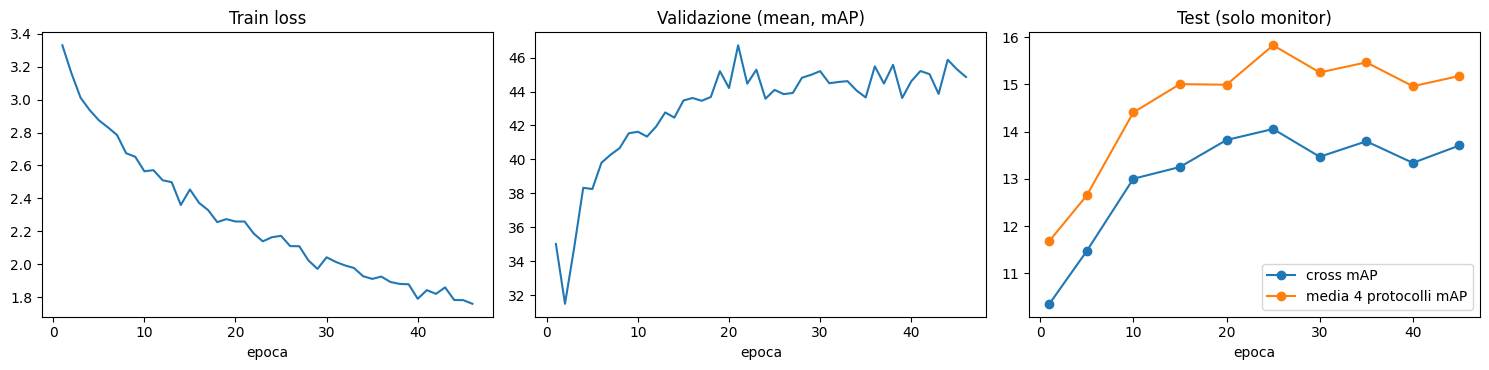

In [8]:
final_model = build_model(n_classes)
final_model.load_state_dict(torch.load(ckpt_path, map_location=device))
embs['Rete addestrata'] = embed_sets(lambda g: extract_features(final_model, g))

print('Chance Rank-1 (test):', chance_line(embs['Rete addestrata']['test']))
print('\n=== TEST ===');  display(results_table(embs, 'test'))
if val_graphs:
    print('=== VAL ===');  display(results_table(embs, 'val'))
print('Righe "+center": embedding di ogni azione centrati sulla propria media (trasduttivo, nessuna etichetta).')

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(history['epoch'], history['loss']); ax[0].set_title('Train loss'); ax[0].set_xlabel('epoca')
ax[1].plot(history['epoch'], history['val']); ax[1].set_title(f"Validazione ({CFG['select_on']}, mAP)"); ax[1].set_xlabel('epoca')
ax[2].plot(history['test_epoch'], history['test_cross'], 'o-', label='cross mAP')
ax[2].plot(history['test_epoch'], history['test_mean'], 'o-', label='media 4 protocolli mAP')
ax[2].set_title('Test (solo monitor)'); ax[2].legend(); ax[2].set_xlabel('epoca')
plt.tight_layout(); plt.show()

## 9. Come leggere i risultati

* **`same_*` alto, `cross` basso** → la rete riconosce le persone ma non attraverso le azioni: il limite è il protocollo cross-azione (prova le righe `+center` e `cross_rev`).
* **`same_*` basso anche per le baseline** → il segnale/preprocessing è il collo di bottiglia: prova `sanitization='hampel'` o `'raw'` in DatasetGeneration v4 e `norm_mode` diverso.
* **Rete addestrata ≈ rete non addestrata ≈ handcrafted** → 22 identità di training sono troppo poche per una rete profonda; la LDA è il riferimento da battere.
* Per la corsa finale metti `val_id_fraction=0` (si addestra su tutte le identità di D1 e si usa l'ultima epoca).
* Ripeti con 3–5 seed (`CFG['seed']`) prima di concludere qualcosa.